In [1]:
import numpy as np
from sklearn.metrics import f1_score, roc_auc_score
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# 1. Device & Seed setup
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
classes = ['CD', 'HYP', 'MI', 'NORM', 'STTC']

# 2. Saved .npy files load karo
X_train = np.load('processed_data/X_train.npy')
y_train = np.load('processed_data/y_train.npy')
X_val = np.load('processed_data/X_val.npy')
y_val = np.load('processed_data/y_val.npy')
X_test = np.load('processed_data/X_test.npy')
y_test = np.load('processed_data/y_test.npy')

# 3. Sirf X_train se Mean & Std nikaal kar teeno ko scale karo
mean = X_train.mean(axis=(0, 1), keepdims=True)
std = X_train.std(axis=(0, 1), keepdims=True) + 1e-8

X_train = np.transpose((X_train - mean) / std, (0, 2, 1))
X_val = np.transpose((X_val - mean) / std, (0, 2, 1))
X_test = np.transpose((X_test - mean) / std, (0, 2, 1))

# 4. DataLoaders taiyaar karo
BATCH_SIZE = 64
train_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.float32),
    ),
    batch_size=BATCH_SIZE,
    shuffle=True,
)
val_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_val, dtype=torch.float32),
        torch.tensor(y_val, dtype=torch.float32),
    ),
    batch_size=BATCH_SIZE,
    shuffle=False,
)
test_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_test, dtype=torch.float32),
        torch.tensor(y_test, dtype=torch.float32),
    ),
    batch_size=BATCH_SIZE,
    shuffle=False,
)

print(
    f'Data Ready on {device} | Train: {X_train.shape}, Val: {X_val.shape},'
    f' Test: {X_test.shape}'
)


Data Ready on cuda | Train: (17111, 12, 1000), Val: (2156, 12, 1000), Test: (2163, 12, 1000)


In [3]:
import copy
import torch.nn.functional as F

# ==========================================
# 1. Seed & Reproducibility
# ==========================================
def seed_everything(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(42)

# ==========================================
# 2. Base Model (Inception1D Reference)
# ==========================================
class InceptionBlock1d(nn.Module):
    def __init__(self, ni, nb_filters=32, kss=(39, 19, 9), bottleneck=32):
        super().__init__()
        self.bottleneck = nn.Conv1d(ni, bottleneck, 1, bias=False) if bottleneck > 0 else nn.Identity()
        bi = bottleneck if bottleneck > 0 else ni
        self.convs = nn.ModuleList([nn.Conv1d(bi, nb_filters, k, padding=k // 2, bias=False) for k in kss])
        self.pool_conv = nn.Sequential(nn.MaxPool1d(3, 1, 1), nn.Conv1d(ni, nb_filters, 1, bias=False))
        self.bn = nn.BatchNorm1d((len(kss) + 1) * nb_filters)

    def forward(self, x):
        b = self.bottleneck(x)
        return F.relu(self.bn(torch.cat([c(b) for c in self.convs] + [self.pool_conv(x)], dim=1)))

class Shortcut1d(nn.Module):
    def __init__(self, ni, nf):
        super().__init__()
        self.conv = nn.Conv1d(ni, nf, 1, bias=False)
        self.bn = nn.BatchNorm1d(nf)

    def forward(self, inp, out):
        return F.relu(out + self.bn(self.conv(inp)))

class BaseInception1d(nn.Module):
    def __init__(self, c_in=12, n_out=5, depth=6, nb_filters=32, kernel_size=40, bottleneck=32):
        super().__init__()
        kss = [kernel_size - 1, kernel_size // 2 - 1, kernel_size // 4 - 1]  # (39, 19, 9)
        nf = (len(kss) + 1) * nb_filters  # 128
        self.blocks = nn.ModuleList([
            InceptionBlock1d(c_in if d == 0 else nf, nb_filters, kss, bottleneck) for d in range(depth)
        ])
        self.shortcuts = nn.ModuleList([
            Shortcut1d(c_in if d == 0 else nf, nf) for d in range(depth // 3)
        ])
        self.head = nn.Sequential(
            nn.BatchNorm1d(2 * nf),
            nn.Dropout(0.25),
            nn.Linear(2 * nf, 128),
            nn.ReLU(inplace=True),
            nn.BatchNorm1d(128),
            nn.Dropout(0.5),
            nn.Linear(128, n_out)
        )

    def forward(self, x):
        res = x
        for d, blk in enumerate(self.blocks):
            x = blk(x)
            if d % 3 == 2:
                x = self.shortcuts[d // 3](res, x)
                res = x
        feat = torch.cat([F.adaptive_avg_pool1d(x, 1), F.adaptive_max_pool1d(x, 1)], dim=1).flatten(1)
        return self.head(feat)

# ==========================================
# 3. Helper Functions (Predict & Thresholds)
# ==========================================
@torch.no_grad()
def get_predictions(model, loader):
    model.eval()
    all_probs, all_targets = [], []
    for xb, yb in loader:
        xb = xb.to(device)
        with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
            logits = model(xb)
        probs = torch.sigmoid(logits).cpu().numpy()
        all_probs.append(probs)
        all_targets.append(yb.numpy())
    return np.vstack(all_probs), np.vstack(all_targets)

def find_best_thresholds(y_true, y_probs):
    best_th = np.zeros(y_true.shape[1])
    grid = np.linspace(0.05, 0.95, 91)
    for j in range(y_true.shape[1]):
        scores = [f1_score(y_true[:, j], y_probs[:, j] >= th, zero_division=0) for th in grid]
        best_th[j] = grid[np.argmax(scores)]
    return best_th

# ==========================================
# 4. Training Loop (RTX 3060 Optimized)
# ==========================================
def train_and_evaluate(model, train_loader, val_loader, test_loader, epochs=40, lr=1e-2, wd=1e-2):
    model = model.to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=lr, epochs=epochs, steps_per_epoch=len(train_loader), pct_start=0.25
    )
    scaler = torch.amp.GradScaler('cuda', enabled=(device.type == 'cuda'))

    best_val_auc = 0.0
    best_weights = None

    for ep in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
                logits = model(xb)
                loss = criterion(logits, yb)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            total_loss += loss.item()

        val_probs, val_targets = get_predictions(model, val_loader)
        val_auc = roc_auc_score(val_targets, val_probs, average='macro')

        mark = ""
        if val_auc > best_val_auc:
            best_val_auc = val_auc
            best_weights = copy.deepcopy(model.state_dict())
            mark = " *"

        print(f"Epoch {ep:02d}/{epochs} | Train Loss: {total_loss/len(train_loader):.4f} | Val Macro-AUROC: {val_auc:.4f}{mark}")

    # Load best validation checkpoint & evaluate on Test (Fold 10)
    model.load_state_dict(best_weights)
    val_probs, val_targets = get_predictions(model, val_loader)
    test_probs, test_targets = get_predictions(model, test_loader)

    thresholds = find_best_thresholds(val_targets, val_probs)
    test_preds = (test_probs >= thresholds).astype(int)

    test_macro_auc = roc_auc_score(test_targets, test_probs, average='macro')
    test_macro_f1 = f1_score(test_targets, test_preds, average='macro', zero_division=0)
    per_class_auc = roc_auc_score(test_targets, test_probs, average=None)

    print("\n" + "=" * 50)
    print(f"FINAL TEST RESULTS (Best Val AUROC: {best_val_auc:.4f})")
    print(f"Test Macro-AUROC : {test_macro_auc:.4f}")
    print(f"Test Macro-F1    : {test_macro_f1:.4f}")
    print("-" * 50)
    for cls_name, auc_val in zip(classes, per_class_auc):
        print(f"  {cls_name:<6}: AUROC = {auc_val:.4f}")
    print("=" * 50)
    return model, test_probs

# Run Base Model
base_model = BaseInception1d(c_in=12, n_out=len(classes))
trained_model, test_probs = train_and_evaluate(base_model, train_loader, val_loader, test_loader, epochs=40)


Epoch 01/40 | Train Loss: 0.4982 | Val Macro-AUROC: 0.8979 *
Epoch 02/40 | Train Loss: 0.3521 | Val Macro-AUROC: 0.9093 *
Epoch 03/40 | Train Loss: 0.3084 | Val Macro-AUROC: 0.9134 *
Epoch 04/40 | Train Loss: 0.2928 | Val Macro-AUROC: 0.9141 *
Epoch 05/40 | Train Loss: 0.2900 | Val Macro-AUROC: 0.9177 *
Epoch 06/40 | Train Loss: 0.2858 | Val Macro-AUROC: 0.9124
Epoch 07/40 | Train Loss: 0.2798 | Val Macro-AUROC: 0.9201 *
Epoch 08/40 | Train Loss: 0.2748 | Val Macro-AUROC: 0.9128
Epoch 09/40 | Train Loss: 0.2724 | Val Macro-AUROC: 0.9161
Epoch 10/40 | Train Loss: 0.2699 | Val Macro-AUROC: 0.9245 *
Epoch 11/40 | Train Loss: 0.2658 | Val Macro-AUROC: 0.9283 *
Epoch 12/40 | Train Loss: 0.2626 | Val Macro-AUROC: 0.9314 *
Epoch 13/40 | Train Loss: 0.2589 | Val Macro-AUROC: 0.9279
Epoch 14/40 | Train Loss: 0.2555 | Val Macro-AUROC: 0.9295
Epoch 15/40 | Train Loss: 0.2520 | Val Macro-AUROC: 0.9272
Epoch 16/40 | Train Loss: 0.2485 | Val Macro-AUROC: 0.9302
Epoch 17/40 | Train Loss: 0.2471 | Val

=== Block 0: Multi-Scale Filter Extraction Share ===
  Kernel 39 (390ms - T/Interval)  : Mean Act = 29.8750 (52.5% share)
  Kernel 19 (190ms - P/ST)        : Mean Act = 15.0969 (26.5% share)
  Kernel 9 (90ms - QRS)           : Mean Act = 11.0399 (19.4% share)
  MaxPool 1x1 (Amplitude)         : Mean Act = 0.9057 (1.6% share)

=== Temporal Focus Summary (Predicted: NORM | Prob: 0.946) ===
  True Labels          : ['NORM']
  Active ECG Window    : 7.8% of the 10s strip has strong filter response (CAM > 0.25)


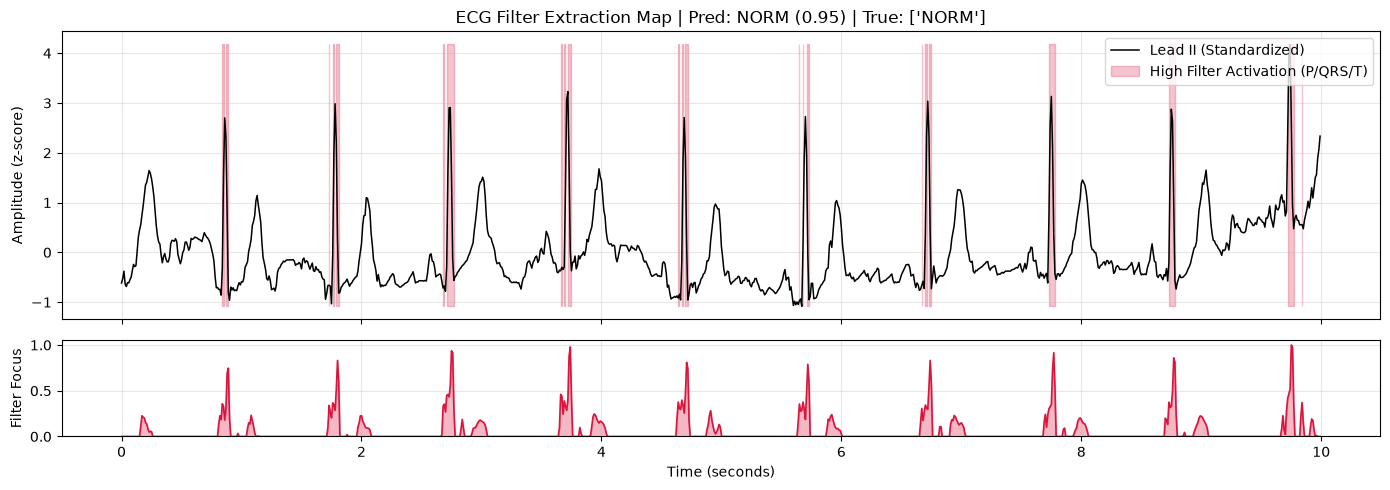

In [4]:
import matplotlib.pyplot as plt

def inspect_filter_extraction(model, sample_x, sample_y, sample_idx=0):
    """
    1. Measures how much activation energy each kernel branch (ks=39, 19, 9, pool) extracts.
    2. Computes Grad-CAM over the 1000-sample ECG to see if P, QRS, and T waves are captured.
    """
    model.eval()
    x = sample_x[sample_idx:sample_idx+1].to(device)  # (1, 12, 1000)
    x.requires_grad_(True)

    # --- Part A: Measure Branch-wise Feature Extraction in Block 0 & Last Block ---
    branch_stats = {}
    with torch.no_grad():
        # Block 0 (Raw ECG -> First Multi-scale Filter Bank)
        b0 = model.blocks[0]
        bn0 = b0.bottleneck(x)
        outs_b0 = [c(bn0) for c in b0.convs] + [b0.pool_conv(x)]
        names = ["Kernel 39 (390ms - T/Interval)", "Kernel 19 (190ms - P/ST)", "Kernel 9 (90ms - QRS)", "MaxPool 1x1 (Amplitude)"]
        
        norms = [o.abs().mean().item() for o in outs_b0]
        total_norm = sum(norms) + 1e-8
        print("=== Block 0: Multi-Scale Filter Extraction Share ===")
        for name, val in zip(names, norms):
            pct = 100.0 * val / total_norm
            branch_stats[name] = pct
            print(f"  {name:<32}: Mean Act = {val:.4f} ({pct:.1f}% share)")

    # --- Part B: Grad-CAM on Final Inception Block (Where P, QRS, T Focus Happens) ---
    activations = []
    gradients = []

    def fwd_hook(module, inp, out):
        activations.append(out)

    def bwd_hook(module, grad_in, grad_out):
        gradients.append(grad_out[0])

    h1 = model.blocks[-1].register_forward_hook(fwd_hook)
    h2 = model.blocks[-1].register_full_backward_hook(bwd_hook)

    logits = model(x)
    probs = torch.sigmoid(logits)[0].detach().cpu().numpy()
    top_cls = int(np.argmax(probs))

    model.zero_grad()
    logits[0, top_cls].backward()

    h1.remove()
    h2.remove()

    act = activations[0][0]          # (128, 1000)
    grad = gradients[0][0]           # (128, 1000)
    weights = grad.mean(dim=1, keepdim=True)  # (128, 1)
    cam = torch.relu((weights * act).sum(dim=0)).detach().cpu().numpy()  # (1000,)
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

    # --- Part C: Quantify How Much of the ECG Signal is Actively Used ---
    active_ratio = (cam > 0.25).mean() * 100.0
    print(f"\n=== Temporal Focus Summary (Predicted: {classes[top_cls]} | Prob: {probs[top_cls]:.3f}) ===")
    print(f"  True Labels          : {[classes[i] for i, v in enumerate(sample_y[sample_idx]) if v == 1]}")
    print(f"  Active ECG Window    : {active_ratio:.1f}% of the 10s strip has strong filter response (CAM > 0.25)")

    # --- Part D: Plot Lead II ECG + Filter Extraction Heatmap ---
    t = np.arange(1000) / 100.0  # seconds (0 to 10s)
    lead_ii = x[0, 1].detach().cpu().numpy()  # Lead II is index 1

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 5), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
    ax1.plot(t, lead_ii, color='black', linewidth=1.1, label='Lead II (Standardized)')
    # Highlight regions where filters extract high information
    ax1.fill_between(t, lead_ii.min(), lead_ii.max(), where=(cam > 0.3), color='crimson', alpha=0.25, label='High Filter Activation (P/QRS/T)')
    ax1.set_title(f"ECG Filter Extraction Map | Pred: {classes[top_cls]} ({probs[top_cls]:.2f}) | True: {[classes[i] for i, v in enumerate(sample_y[sample_idx]) if v == 1]}")
    ax1.set_ylabel("Amplitude (z-score)")
    ax1.legend(loc="upper right")
    ax1.grid(alpha=0.3)

    ax2.plot(t, cam, color='crimson', linewidth=1.2)
    ax2.fill_between(t, 0, cam, color='crimson', alpha=0.3)
    ax2.set_ylabel("Filter Focus")
    ax2.set_xlabel("Time (seconds)")
    ax2.set_ylim(0, 1.05)
    ax2.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

# Run inspection on a batch from test_loader
xb_test, yb_test = next(iter(test_loader))
inspect_filter_extraction(trained_model, xb_test, yb_test, sample_idx=0)


In [5]:
import pandas as pd
from scipy.signal import find_peaks

# ==========================================
# 1. Multi-Kernel Filter Bank Probe (7 Distinct Filter Scales)
# ==========================================
KERNEL_SCALES = [3, 5, 9, 15, 19, 29, 39]  # 30ms to 390ms @ 100Hz

class MultiFilterProbe(nn.Module):
    """
    Tests 7 distinct 1D CNN filter widths in parallel to measure which filter
    captures P-wave, QRS-complex, and T-wave best across all 5 superclasses.
    """
    def __init__(self, c_in=12, n_out=5, filters_per_kernel=24):
        super().__init__()
        self.kernels = KERNEL_SCALES
        self.branches = nn.ModuleList([
            nn.Sequential(
                nn.Conv1d(c_in, filters_per_kernel, kernel_size=k, padding=k // 2, bias=False),
                nn.BatchNorm1d(filters_per_kernel),
                nn.ReLU(inplace=True),
                nn.Conv1d(filters_per_kernel, filters_per_kernel, kernel_size=k, padding=k // 2, bias=False),
                nn.BatchNorm1d(filters_per_kernel),
                nn.ReLU(inplace=True),
            ) for k in self.kernels
        ])
        total_ch = filters_per_kernel * len(self.kernels)
        self.head = nn.Sequential(
            nn.BatchNorm1d(2 * total_ch),
            nn.Dropout(0.3),
            nn.Linear(2 * total_ch, 128),
            nn.ReLU(inplace=True),
            nn.Linear(128, n_out)
        )

    def forward(self, x, return_branches=False):
        branch_outs = [branch(x) for branch in self.branches]  # list of (B, F, 1000)
        if return_branches:
            return branch_outs
        feat_map = torch.cat(branch_outs, dim=1)
        pooled = torch.cat([F.adaptive_avg_pool1d(feat_map, 1), F.adaptive_max_pool1d(feat_map, 1)], dim=1).flatten(1)
        return self.head(pooled)

# ==========================================
# 2. P, QRS, T Ground-Truth Window Delineator (100 Hz)
# ==========================================
def get_pqrst_masks(ecg_1d, fs=100):
    """
    Creates binary temporal masks (length 1000) for P-wave, QRS-complex, and T-wave
    anchored around detected R-peaks on Lead II.
    """
    L = len(ecg_1d)
    p_mask = np.zeros(L, dtype=np.float32)
    qrs_mask = np.zeros(L, dtype=np.float32)
    t_mask = np.zeros(L, dtype=np.float32)

    # Detect R-peaks (minimum distance 0.4s = 40 samples)
    sig_norm = (ecg_1d - np.mean(ecg_1d)) / (np.std(ecg_1d) + 1e-8)
    peaks, _ = find_peaks(np.abs(sig_norm), distance=int(0.4 * fs), prominence=1.0)

    for r in peaks:
        # QRS complex: [R - 50ms, R + 50ms] -> [r-5, r+5]
        qrs_mask[max(0, r - 5):min(L, r + 6)] = 1.0
        # P wave: [R - 200ms, R - 80ms] -> [r-20, r-8]
        p_mask[max(0, r - 20):max(0, r - 7)] = 1.0
        # T wave: [R + 100ms, R + 350ms] -> [r+10, r+35]
        t_mask[min(L, r + 10):min(L, r + 36)] = 1.0

    return p_mask, qrs_mask, t_mask

# ==========================================
# 3. Measure Wave Detection Capability & Class-Wise Filter Share
# ==========================================
def analyze_filters_across_classes(probe_model, test_loader, max_batches=15):
    probe_model.eval()
    n_k = len(KERNEL_SCALES)
    n_c = len(classes)

    # Accumulators for P, QRS, T sensitivity per kernel
    wave_energy = {k: {"P": [], "QRS": [], "T": [], "Baseline": []} for k in KERNEL_SCALES}
    # Accumulator for Class-wise Gradient Share (%) per kernel
    class_filter_share = np.zeros((n_c, n_k), dtype=np.float64)
    class_counts = np.zeros(n_c, dtype=np.float64)

    for b_idx, (xb, yb) in enumerate(test_loader):
        if b_idx >= max_batches:
            break
        xb = xb.to(device)
        xb.requires_grad_(True)

        branch_outs = probe_model(xb, return_branches=True)  # 7 tensors of (B, F, 1000)
        feat_map = torch.cat(branch_outs, dim=1)
        pooled = torch.cat([F.adaptive_avg_pool1d(feat_map, 1), F.adaptive_max_pool1d(feat_map, 1)], dim=1).flatten(1)
        logits = probe_model.head(pooled)

        # --- A. Measure P, QRS, T Detection Capability per Filter ---
        with torch.no_grad():
            xb_np = xb.detach().cpu().numpy()
            for i in range(len(xb)):
                p_m, qrs_m, t_m = get_pqrst_masks(xb_np[i, 1])  # Lead II
                if qrs_m.sum() == 0:
                    continue
                base_m = 1.0 - np.clip(p_m + qrs_m + t_m, 0, 1)

                for k_idx, k in enumerate(KERNEL_SCALES):
                    # Mean activation curve across channels for kernel k -> (1000,)
                    act_curve = branch_outs[k_idx][i].mean(dim=0).cpu().numpy()
                    act_curve = act_curve / (act_curve.max() + 1e-8)

                    wave_energy[k]["P"].append(act_curve[p_m == 1].mean() if p_m.sum() > 0 else 0.0)
                    wave_energy[k]["QRS"].append(act_curve[qrs_m == 1].mean())
                    wave_energy[k]["T"].append(act_curve[t_m == 1].mean() if t_m.sum() > 0 else 0.0)
                    wave_energy[k]["Baseline"].append(act_curve[base_m == 1].mean() if base_m.sum() > 0 else 0.0)

        # --- B. Measure Class-Wise Filter Contribution (%) for all 5 Superclasses ---
        for c_idx in range(n_c):
            pos_mask = (yb[:, c_idx] == 1)
            if pos_mask.sum() == 0:
                continue
            probe_model.zero_grad()
            # Retain grads on branch outputs
            for bo in branch_outs:
                bo.retain_grad()

            target_score = logits[pos_mask, c_idx].sum()
            target_score.backward(retain_graph=True)

            # Grad * Activation importance per kernel
            k_scores = []
            for k_idx in range(n_k):
                imp = (branch_outs[k_idx].grad[pos_mask] * branch_outs[k_idx][pos_mask]).abs().mean().item()
                k_scores.append(imp)
            k_scores = np.array(k_scores)
            class_filter_share[c_idx] += (k_scores / (k_scores.sum() + 1e-8)) * 100.0
            class_counts[c_idx] += 1

    # Format Results into Clean Tables
    wave_rows = []
    for k in KERNEL_SCALES:
        p_val = np.mean(wave_energy[k]["P"])
        qrs_val = np.mean(wave_energy[k]["QRS"])
        t_val = np.mean(wave_energy[k]["T"])
        base_val = np.mean(wave_energy[k]["Baseline"]) + 1e-8
        wave_rows.append({
            "Filter_Kernel": f"ks={k} ({k*10}ms)",
            "P_Wave_Response": round(p_val, 4),
            "QRS_Response": round(qrs_val, 4),
            "T_Wave_Response": round(t_val, 4),
            "Baseline_Noise": round(base_val, 4),
            "Wave_to_Baseline_SNR": round((p_val + qrs_val + t_val) / (3 * base_val), 2)
        })
    df_waves = pd.DataFrame(wave_rows)

    class_filter_share = class_filter_share / np.maximum(class_counts[:, None], 1)
    df_classes = pd.DataFrame(
        np.round(class_filter_share, 2),
        index=classes,
        columns=[f"ks={k} (%)" for k in KERNEL_SCALES]
    )

    print("\n=== TABLE 1: P, QRS, T Wave Detection Capability by CNN Filter Width ===")
    print(df_waves.to_string(index=False))

    print("\n=== TABLE 2: Filter Importance Share (%) Across All 5 Superclasses ===")
    print(df_classes.to_string())
    return df_waves, df_classes

# Train the 7-Filter Probe for 15 fast epochs (~1 min on RTX 3060) & run analysis
probe = MultiFilterProbe(c_in=12, n_out=5, filters_per_kernel=24)
probe, _ = train_and_evaluate(probe, train_loader, val_loader, test_loader, epochs=15, lr=5e-3)
df_waves, df_classes = analyze_filters_across_classes(probe, test_loader)


Epoch 01/15 | Train Loss: 0.3941 | Val Macro-AUROC: 0.8938 *
Epoch 02/15 | Train Loss: 0.3156 | Val Macro-AUROC: 0.8995 *
Epoch 03/15 | Train Loss: 0.3091 | Val Macro-AUROC: 0.9041 *
Epoch 04/15 | Train Loss: 0.2983 | Val Macro-AUROC: 0.9145 *
Epoch 05/15 | Train Loss: 0.2887 | Val Macro-AUROC: 0.9160 *
Epoch 06/15 | Train Loss: 0.2762 | Val Macro-AUROC: 0.9243 *
Epoch 07/15 | Train Loss: 0.2695 | Val Macro-AUROC: 0.9196
Epoch 08/15 | Train Loss: 0.2622 | Val Macro-AUROC: 0.9200
Epoch 09/15 | Train Loss: 0.2523 | Val Macro-AUROC: 0.9234
Epoch 10/15 | Train Loss: 0.2448 | Val Macro-AUROC: 0.9253 *
Epoch 11/15 | Train Loss: 0.2354 | Val Macro-AUROC: 0.9259 *
Epoch 12/15 | Train Loss: 0.2265 | Val Macro-AUROC: 0.9285 *
Epoch 13/15 | Train Loss: 0.2169 | Val Macro-AUROC: 0.9302 *
Epoch 14/15 | Train Loss: 0.2110 | Val Macro-AUROC: 0.9286
Epoch 15/15 | Train Loss: 0.2082 | Val Macro-AUROC: 0.9294

FINAL TEST RESULTS (Best Val AUROC: 0.9302)
Test Macro-AUROC : 0.9268
Test Macro-F1    : 0.746

In [7]:
class MorphoInception1d(nn.Module):
    """
    Modified Inception1D using our empirically selected P-QRS-T optimal filter bank:
    - ks=39 (390ms): T-wave & STTC repolarization
    - ks=15 (150ms): P-wave & wide QRS (CD)
    - ks=9  (90ms) : Normal QRS & HYP
    - ks=5  (50ms) : Sharp pathological Q-waves (MI) & high-SNR R-peaks
    """
    def __init__(self, c_in=12, n_out=5, depth=6, nb_filters=26, kss=(39, 15, 9, 5), bottleneck=32):
        super().__init__()
        self.kss = kss
        nf = (len(kss) + 1) * nb_filters  # 5 * 26 = 130 channels (same capacity as baseline 128)
        self.blocks = nn.ModuleList([
            InceptionBlock1d(c_in if d == 0 else nf, nb_filters, kss, bottleneck) for d in range(depth)
        ])
        self.shortcuts = nn.ModuleList([
            Shortcut1d(c_in if d == 0 else nf, nf) for d in range(depth // 3)
        ])
        self.head = nn.Sequential(
            nn.BatchNorm1d(2 * nf),
            nn.Dropout(0.25),
            nn.Linear(2 * nf, 128),
            nn.ReLU(inplace=True),
            nn.BatchNorm1d(128),
            nn.Dropout(0.5),
            nn.Linear(128, n_out)
        )

    def forward(self, x):
        res = x
        for d, blk in enumerate(self.blocks):
            x = blk(x)
            if d % 3 == 2:
                x = self.shortcuts[d // 3](res, x)
                res = x
        feat = torch.cat([F.adaptive_avg_pool1d(x, 1), F.adaptive_max_pool1d(x, 1)], dim=1).flatten(1)
        return self.head(feat)

# Train & Evaluate with exact same hyperparams & early stopping as Baseline
seed_everything(42)
morpho_inception = MorphoInception1d(c_in=12, n_out=len(classes), nb_filters=26, kss=(39, 15, 9, 5))
print(f"Total Parameters: {sum(p.numel() for p in morpho_inception.parameters()) / 1e6:.3f}M")

trained_morpho, morpho_test_probs = train_and_evaluate(
    morpho_inception, train_loader, val_loader, test_loader, epochs=40, lr=1e-2, wd=1e-2
)


Total Parameters: 0.433M
Epoch 01/40 | Train Loss: 0.4962 | Val Macro-AUROC: 0.8932 *
Epoch 02/40 | Train Loss: 0.3495 | Val Macro-AUROC: 0.9097 *
Epoch 03/40 | Train Loss: 0.3067 | Val Macro-AUROC: 0.8995
Epoch 04/40 | Train Loss: 0.2939 | Val Macro-AUROC: 0.9155 *
Epoch 05/40 | Train Loss: 0.2913 | Val Macro-AUROC: 0.9155
Epoch 06/40 | Train Loss: 0.2839 | Val Macro-AUROC: 0.9201 *
Epoch 07/40 | Train Loss: 0.2826 | Val Macro-AUROC: 0.9185
Epoch 08/40 | Train Loss: 0.2776 | Val Macro-AUROC: 0.9188
Epoch 09/40 | Train Loss: 0.2716 | Val Macro-AUROC: 0.9267 *
Epoch 10/40 | Train Loss: 0.2680 | Val Macro-AUROC: 0.9271 *
Epoch 11/40 | Train Loss: 0.2645 | Val Macro-AUROC: 0.9225
Epoch 12/40 | Train Loss: 0.2609 | Val Macro-AUROC: 0.9231
Epoch 13/40 | Train Loss: 0.2596 | Val Macro-AUROC: 0.9269
Epoch 14/40 | Train Loss: 0.2557 | Val Macro-AUROC: 0.9239
Epoch 15/40 | Train Loss: 0.2528 | Val Macro-AUROC: 0.9288 *
Epoch 16/40 | Train Loss: 0.2511 | Val Macro-AUROC: 0.9279
Epoch 17/40 | Tra

In [8]:
# ==========================================
# 1. Mehari et al. (2022) GPU Augmentations (RRC + TimeOut)
# ==========================================
def apply_ecg_augmentations(xb, p=0.5):
    B, C, L = xb.shape
    # Random Resized Crop (heart rate / wave stretching invariance)
    if torch.rand(1).item() < p:
        scale = torch.empty(B, 1, device=xb.device).uniform_(0.6, 1.0)
        start = torch.rand(B, 1, device=xb.device) * (1.0 - scale)
        u = torch.linspace(0, 1, L, device=xb.device)[None]
        gx = (start + scale * u) * 2.0 - 1.0
        grid = torch.stack([gx, torch.zeros_like(gx)], dim=-1)[:, None]
        xb = F.grid_sample(xb[:, :, None], grid, mode='bilinear', align_corners=True)[:, :, 0]

    # Time Out (forces model to check all beats, not memorize one spike)
    if torch.rand(1).item() < p:
        t = torch.empty(B, 1, device=xb.device).uniform_(0.0, 0.35)
        s = torch.rand(B, 1, device=xb.device) * (1.0 - t)
        pos = torch.linspace(0, 1, L, device=xb.device)[None]
        keep = ~((pos >= s) & (pos < s + t))
        xb = xb * keep[:, None].to(xb.dtype)
    return xb

# ==========================================
# 2. Sliding-Window Test-Time Augmentation (TTA) Predictor
# ==========================================
@torch.no_grad()
def predict_sliding_tta(model, loader, win=250, stride=125):
    model.eval()
    all_probs, all_targets = [], []
    for xb, yb in loader:
        xb = xb.to(device)
        B, C, L = xb.shape
        starts = list(range(0, L - win + 1, stride))
        if starts[-1] != L - win:
            starts.append(L - win)

        # Extract all 2.5s windows across the 10s ECG
        windows = torch.stack([xb[:, :, s:s + win] for s in starts], dim=1)  # (B, n_win, C, win)
        flat_w = windows.view(B * len(starts), C, win)

        with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
            logits = model(flat_w)
        probs = torch.sigmoid(logits).view(B, len(starts), -1)
        # Max probability across windows (Strodthoff benchmark rule)
        agg_probs = probs.max(dim=1)[0].cpu().numpy()

        all_probs.append(agg_probs)
        all_targets.append(yb.numpy())
    return np.vstack(all_probs), np.vstack(all_targets)

# ==========================================
# 3. Windowed Training Loop + Early Stopping
# ==========================================
def train_windowed_tta(model, train_loader, val_loader, test_loader, epochs=50, lr=1e-2, wd=1e-2, win=250, patience=10):
    model = model.to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=lr, epochs=epochs, steps_per_epoch=len(train_loader), pct_start=0.25
    )
    scaler = torch.amp.GradScaler('cuda', enabled=(device.type == 'cuda'))

    best_val_auc = 0.0
    best_weights = None
    no_improve = 0
    warmup_ep = int(epochs * 0.25)

    for ep in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            # Random 2.5s crop per sample in batch
            B, C, L = xb.shape
            st = torch.randint(0, L - win + 1, (B,), device=device)
            idx = (st[:, None] + torch.arange(win, device=device)[None])[:, None].expand(-1, C, -1)
            xb_crop = torch.gather(xb, 2, idx)
            xb_crop = apply_ecg_augmentations(xb_crop, p=0.5)

            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
                logits = model(xb_crop)
                loss = criterion(logits, yb)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            total_loss += loss.item()

        val_probs, val_targets = predict_sliding_tta(model, val_loader, win=win)
        val_auc = roc_auc_score(val_targets, val_probs, average='macro')

        mark = ""
        if val_auc > best_val_auc + 1e-4:
            best_val_auc = val_auc
            best_weights = copy.deepcopy(model.state_dict())
            no_improve = 0
            mark = " *"
        elif ep > warmup_ep:
            no_improve += 1

        print(f"Epoch {ep:02d}/{epochs} | Loss: {total_loss/len(train_loader):.4f} | Val TTA-AUROC: {val_auc:.4f}{mark}")
        if ep > warmup_ep and no_improve >= patience:
            print(f"--> Early stopping triggered at epoch {ep}.")
            break

    model.load_state_dict(best_weights)
    val_probs, val_targets = predict_sliding_tta(model, val_loader, win=win)
    test_probs, test_targets = predict_sliding_tta(model, test_loader, win=win)

    thresholds = find_best_thresholds(val_targets, val_probs)
    test_preds = (test_probs >= thresholds).astype(int)

    print("\n" + "=" * 50)
    print(f"FINAL TTA TEST RESULTS (Best Val AUROC: {best_val_auc:.4f})")
    print(f"Test Macro-AUROC : {roc_auc_score(test_targets, test_probs, average='macro'):.4f}")
    print(f"Test Macro-F1    : {f1_score(test_targets, test_preds, average='macro', zero_division=0):.4f}")
    print("-" * 50)
    for cls_name, auc_val in zip(classes, roc_auc_score(test_targets, test_probs, average=None)):
        print(f"  {cls_name:<6}: AUROC = {auc_val:.4f}")
    print("=" * 50)
    return model, test_probs

# Run exact same MorphoInception1d (0.433M params) with 2.5s Windowing + Aug + TTA
seed_everything(42)
morpho_inception_tta = MorphoInception1d(c_in=12, n_out=len(classes), nb_filters=26, kss=(39, 15, 9, 5))
trained_morpho_tta, morpho_tta_probs = train_windowed_tta(
    morpho_inception_tta, train_loader, val_loader, test_loader, epochs=50, lr=1e-2, wd=1e-2, win=250, patience=10
)


Epoch 01/50 | Loss: 0.5204 | Val TTA-AUROC: 0.8874 *
Epoch 02/50 | Loss: 0.3758 | Val TTA-AUROC: 0.9031 *
Epoch 03/50 | Loss: 0.3270 | Val TTA-AUROC: 0.9026
Epoch 04/50 | Loss: 0.3191 | Val TTA-AUROC: 0.9091 *
Epoch 05/50 | Loss: 0.3074 | Val TTA-AUROC: 0.9134 *
Epoch 06/50 | Loss: 0.3058 | Val TTA-AUROC: 0.9156 *
Epoch 07/50 | Loss: 0.3023 | Val TTA-AUROC: 0.9168 *
Epoch 08/50 | Loss: 0.3015 | Val TTA-AUROC: 0.9223 *
Epoch 09/50 | Loss: 0.2979 | Val TTA-AUROC: 0.9155
Epoch 10/50 | Loss: 0.2949 | Val TTA-AUROC: 0.9222
Epoch 11/50 | Loss: 0.2907 | Val TTA-AUROC: 0.9181
Epoch 12/50 | Loss: 0.2915 | Val TTA-AUROC: 0.9177
Epoch 13/50 | Loss: 0.2869 | Val TTA-AUROC: 0.9207
Epoch 14/50 | Loss: 0.2839 | Val TTA-AUROC: 0.9225 *
Epoch 15/50 | Loss: 0.2835 | Val TTA-AUROC: 0.9184
Epoch 16/50 | Loss: 0.2825 | Val TTA-AUROC: 0.9220
Epoch 17/50 | Loss: 0.2806 | Val TTA-AUROC: 0.9268 *
Epoch 18/50 | Loss: 0.2774 | Val TTA-AUROC: 0.9268
Epoch 19/50 | Loss: 0.2772 | Val TTA-AUROC: 0.9259
Epoch 20/50 |

In [9]:
# ==========================================
# 1. Squeeze-and-Excitation (Filter/Channel Attention)
# ==========================================
class SEBlock1d(nn.Module):
    def __init__(self, channels, reduction=8):
        super().__init__()
        self.fc = nn.Sequential(
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Linear(channels, channels // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channels // reduction, channels, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        w = self.fc(x).unsqueeze(-1)  # (B, C, 1)
        return x * w

# ==========================================
# 2. Morpho-Inception Block + SE Attention
# ==========================================
class MorphoSEBlock1d(nn.Module):
    def __init__(self, ni, nb_filters=26, kss=(39, 15, 9, 5), bottleneck=32):
        super().__init__()
        self.bottleneck = nn.Conv1d(ni, bottleneck, 1, bias=False) if bottleneck > 0 else nn.Identity()
        bi = bottleneck if bottleneck > 0 else ni
        self.convs = nn.ModuleList([
            nn.Conv1d(bi, nb_filters, k, padding=k // 2, bias=False) for k in kss
        ])
        self.pool_conv = nn.Sequential(
            nn.MaxPool1d(3, 1, 1),
            nn.Conv1d(ni, nb_filters, 1, bias=False)
        )
        out_ch = (len(kss) + 1) * nb_filters
        self.bn = nn.BatchNorm1d(out_ch)
        self.se = SEBlock1d(out_ch, reduction=8)

    def forward(self, x):
        b = self.bottleneck(x)
        out = torch.cat([c(b) for c in self.convs] + [self.pool_conv(x)], dim=1)
        out = F.relu(self.bn(out))
        return self.se(out)

# ==========================================
# 3. 3-Head Physiological Wave-Attention Pooling (P, QRS, T Heads)
# ==========================================
class WaveAttentionPool1d(nn.Module):
    """
    Replaces naive global average pooling with 3 specialized temporal attention heads
    designed to isolate P-wave, QRS-complex, and ST/T-wave regions while ignoring baseline.
    """
    def __init__(self, in_channels, n_heads=3):
        super().__init__()
        self.n_heads = n_heads
        self.attn_conv = nn.Sequential(
            nn.Conv1d(in_channels, in_channels // 2, kernel_size=5, padding=2, bias=False),
            nn.Tanh(),
            nn.Conv1d(in_channels // 2, n_heads, kernel_size=1, bias=True)
        )

    def forward(self, x, return_weights=False):
        # x: (B, C, T)
        scores = self.attn_conv(x)                     # (B, 3, T)
        weights = F.softmax(scores, dim=-1)            # (B, 3, T) normalized over time
        # Weighted sum over time for each of the 3 heads -> (B, 3, C)
        attended = torch.bmm(weights, x.transpose(1, 2)).flatten(1)  # (B, 3*C)
        # Combine with global max pool to preserve peak QRS/R-wave voltage (crucial for HYP)
        max_p = F.adaptive_max_pool1d(x, 1).flatten(1)               # (B, C)
        out = torch.cat([attended, max_p], dim=1)                    # (B, 4*C)
        if return_weights:
            return out, weights
        return out

# ==========================================
# 4. Full Upgraded Model: MorphoWaveNet
# ==========================================
class MorphoWaveNet(nn.Module):
    def __init__(self, c_in=12, n_out=5, depth=6, nb_filters=26, kss=(39, 15, 9, 5), bottleneck=32):
        super().__init__()
        # Upgrade 1: Lead-Preserving Spatial Stem (4 filters per lead before cross-lead mixing)
        stem_ch = c_in * 4  # 48 channels
        self.lead_stem = nn.Sequential(
            nn.Conv1d(c_in, stem_ch, kernel_size=7, padding=3, groups=c_in, bias=False),
            nn.BatchNorm1d(stem_ch),
            nn.ReLU(inplace=True),
            nn.Conv1d(stem_ch, stem_ch, kernel_size=1, bias=False),
            nn.BatchNorm1d(stem_ch),
            nn.ReLU(inplace=True)
        )

        # Upgrade 2: Multi-Scale Morpho-Inception + SE Channel Attention
        nf = (len(kss) + 1) * nb_filters  # 130 channels
        self.blocks = nn.ModuleList([
            MorphoSEBlock1d(stem_ch if d == 0 else nf, nb_filters, kss, bottleneck)
            for d in range(depth)
        ])
        self.shortcuts = nn.ModuleList([
            Shortcut1d(stem_ch if d == 0 else nf, nf)
            for d in range(depth // 3)
        ])

        # Upgrade 3: 3-Head Wave-Attention Pooling + MaxPool
        self.wave_pool = WaveAttentionPool1d(nf, n_heads=3)
        pooled_dim = 4 * nf  # 3 attention heads + 1 max pool = 520

        self.head = nn.Sequential(
            nn.BatchNorm1d(pooled_dim),
            nn.Dropout(0.3),
            nn.Linear(pooled_dim, 160),
            nn.ReLU(inplace=True),
            nn.BatchNorm1d(160),
            nn.Dropout(0.5),
            nn.Linear(160, n_out)
        )

    def forward(self, x, return_attn=False):
        x = self.lead_stem(x)
        res = x
        for d, blk in enumerate(self.blocks):
            x = blk(x)
            if d % 3 == 2:
                x = self.shortcuts[d // 3](res, x)
                res = x
        if return_attn:
            feat, attn_w = self.wave_pool(x, return_weights=True)
            return self.head(feat), attn_w
        feat = self.wave_pool(x)
        return self.head(feat)

# Run Upgraded MorphoWaveNet with exact same Windowed + Aug + TTA protocol
seed_everything(42)
morpho_wavenet = MorphoWaveNet(c_in=12, n_out=len(classes), nb_filters=26, kss=(39, 15, 9, 5))
print(f"MorphoWaveNet Parameters: {sum(p.numel() for p in morpho_wavenet.parameters()) / 1e6:.3f}M")

trained_wavenet, wavenet_test_probs = train_windowed_tta(
    morpho_wavenet,
    train_loader,
    val_loader,
    test_loader,
    epochs=50,
    lr=8e-3,      # slightly smoother LR for attention heads
    wd=1.5e-2,
    win=250,
    patience=12
)


MorphoWaveNet Parameters: 0.561M
Epoch 01/50 | Loss: 0.5199 | Val TTA-AUROC: 0.8962 *
Epoch 02/50 | Loss: 0.3789 | Val TTA-AUROC: 0.9071 *
Epoch 03/50 | Loss: 0.3189 | Val TTA-AUROC: 0.9051
Epoch 04/50 | Loss: 0.3064 | Val TTA-AUROC: 0.9091 *
Epoch 05/50 | Loss: 0.2979 | Val TTA-AUROC: 0.9160 *
Epoch 06/50 | Loss: 0.2978 | Val TTA-AUROC: 0.9195 *
Epoch 07/50 | Loss: 0.2928 | Val TTA-AUROC: 0.9126
Epoch 08/50 | Loss: 0.2916 | Val TTA-AUROC: 0.9158
Epoch 09/50 | Loss: 0.2907 | Val TTA-AUROC: 0.9214 *
Epoch 10/50 | Loss: 0.2862 | Val TTA-AUROC: 0.9182
Epoch 11/50 | Loss: 0.2826 | Val TTA-AUROC: 0.9189
Epoch 12/50 | Loss: 0.2817 | Val TTA-AUROC: 0.9266 *
Epoch 13/50 | Loss: 0.2824 | Val TTA-AUROC: 0.9242
Epoch 14/50 | Loss: 0.2817 | Val TTA-AUROC: 0.9253
Epoch 15/50 | Loss: 0.2780 | Val TTA-AUROC: 0.9232
Epoch 16/50 | Loss: 0.2775 | Val TTA-AUROC: 0.9248
Epoch 17/50 | Loss: 0.2758 | Val TTA-AUROC: 0.9270 *
Epoch 18/50 | Loss: 0.2757 | Val TTA-AUROC: 0.9266
Epoch 19/50 | Loss: 0.2712 | Val 

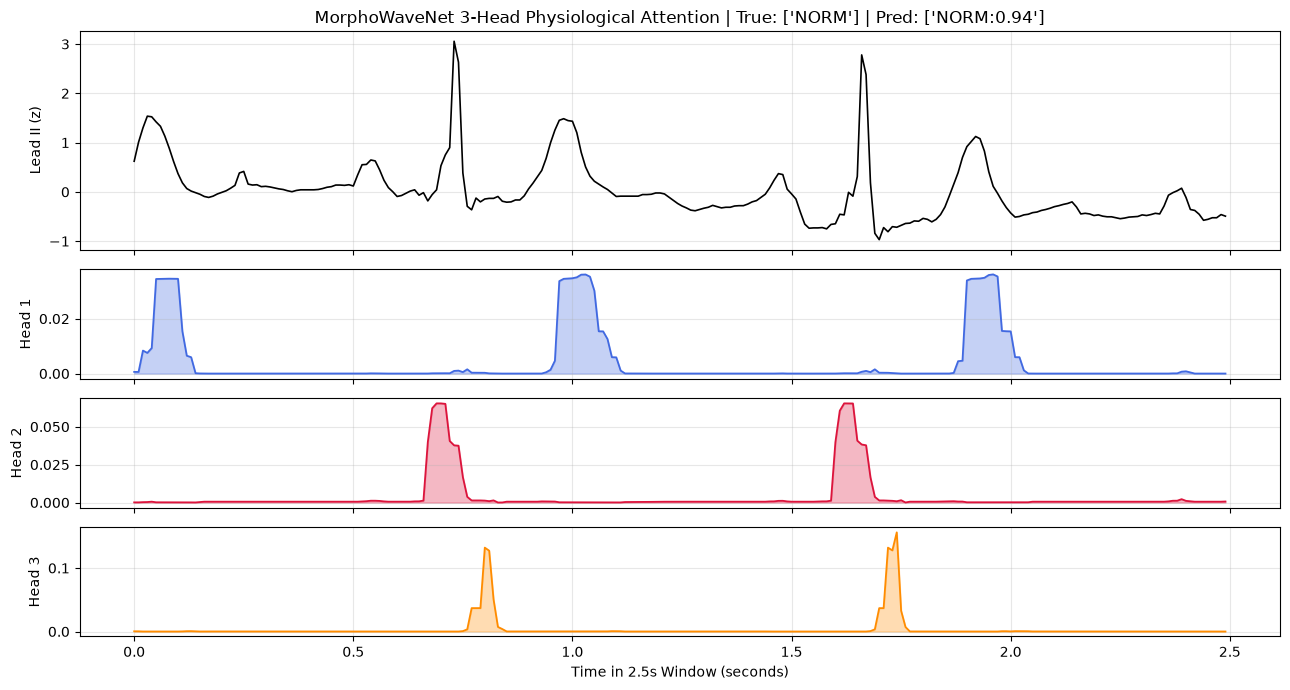

In [11]:
@torch.no_grad()
def plot_wave_attention_heads(model, loader, sample_idx=2, win=250):
    model.eval()
    xb, yb = next(iter(loader))
    xb_win = xb[sample_idx:sample_idx+1, :, 375:375 + win].to(device)
    logits, attn_w = model(xb_win, return_attn=True)
    
    probs = torch.sigmoid(logits).squeeze(0).cpu().numpy()   # shape: (5,)
    attn = attn_w.squeeze(0).cpu().numpy()                   # shape: (3, 250)
    lead_ii = xb_win[0, 1].cpu().numpy()                     # shape: (250,) -> Lead II
    t = np.arange(win) / 100.0

    true_lbls = [classes[i] for i, v in enumerate(yb[sample_idx]) if v == 1]
    pred_lbls = [f"{classes[i]}:{probs[i]:.2f}" for i in range(len(classes)) if probs[i] > 0.4]

    fig, axes = plt.subplots(4, 1, figsize=(13, 7), sharex=True, gridspec_kw={'height_ratios': [2, 1, 1, 1]})
    axes[0].plot(t, lead_ii, color='black', lw=1.2)
    axes[0].set_title(f"MorphoWaveNet 3-Head Physiological Attention | True: {true_lbls} | Pred: {pred_lbls}")
    axes[0].set_ylabel("Lead II (z)")
    axes[0].grid(alpha=0.3)

    colors = ['royalblue', 'crimson', 'darkorange']
    for h in range(3):
        axes[h + 1].plot(t, attn[h], color=colors[h], lw=1.3)
        axes[h + 1].fill_between(t, 0, attn[h], color=colors[h], alpha=0.3)
        axes[h + 1].set_ylabel(f"Head {h+1}")
        axes[h + 1].grid(alpha=0.3)

    axes[-1].set_xlabel("Time in 2.5s Window (seconds)")
    plt.tight_layout()
    plt.show()

plot_wave_attention_heads(trained_wavenet, test_loader, sample_idx=2)


In [5]:
import copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import roc_auc_score
import plotly.graph_objects as go

# ==========================================
# 1. Device, Seed & Data Loading
# ==========================================
def seed_everything(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = device.type == 'cuda'
classes = ['CD', 'HYP', 'MI', 'NORM', 'STTC']
LEAD_NAMES = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']   # PTB-XL order
LEAD_II = 1
FS = 100

X_train = np.load('processed_data/X_train.npy')   # (N, L, 12)
y_train = np.load('processed_data/y_train.npy')
X_val   = np.load('processed_data/X_val.npy')
y_val   = np.load('processed_data/y_val.npy')
X_test  = np.load('processed_data/X_test.npy')
y_test  = np.load('processed_data/y_test.npy')

# per-lead standardization, statistics from the training set only
mean = X_train.mean(axis=(0, 1), keepdims=True)
std  = X_train.std(axis=(0, 1), keepdims=True) + 1e-8

X_train = np.transpose((X_train - mean) / std, (0, 2, 1))   # -> (N, 12, L)
X_val   = np.transpose((X_val - mean) / std, (0, 2, 1))
X_test  = np.transpose((X_test - mean) / std, (0, 2, 1))

BATCH_SIZE = 64
def make_loader(X, y, shuffle):
    ds = TensorDataset(torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.float32))
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle)
train_loader = make_loader(X_train, y_train, True)
val_loader   = make_loader(X_val, y_val, False)
test_loader  = make_loader(X_test, y_test, False)

# ==========================================
# 2. MorphoWaveNet Architecture
# ==========================================
class SEBlock1d(nn.Module):
    def __init__(self, channels, reduction=8):
        super().__init__()
        self.fc = nn.Sequential(
            nn.AdaptiveAvgPool1d(1), nn.Flatten(),
            nn.Linear(channels, channels // reduction, bias=False), nn.ReLU(inplace=True),
            nn.Linear(channels // reduction, channels, bias=False), nn.Sigmoid()
        )
    def forward(self, x):
        return x * self.fc(x).unsqueeze(-1)

class MorphoSEBlock1d(nn.Module):
    def __init__(self, ni, nb_filters=26, kss=(39, 15, 9, 5), bottleneck=32):
        super().__init__()
        self.kss = kss
        self.bottleneck = nn.Conv1d(ni, bottleneck, 1, bias=False) if bottleneck > 0 else nn.Identity()
        bi = bottleneck if bottleneck > 0 else ni
        self.convs = nn.ModuleList([nn.Conv1d(bi, nb_filters, k, padding=k // 2, bias=False) for k in kss])
        self.pool_conv = nn.Sequential(nn.MaxPool1d(3, 1, 1), nn.Conv1d(ni, nb_filters, 1, bias=False))
        out_ch = (len(kss) + 1) * nb_filters
        self.bn = nn.BatchNorm1d(out_ch)
        self.se = SEBlock1d(out_ch, reduction=8)

    def forward(self, x):
        b = self.bottleneck(x)
        out = F.relu(self.bn(torch.cat([c(b) for c in self.convs] + [self.pool_conv(x)], dim=1)))
        return self.se(out)

class Shortcut1d(nn.Module):
    def __init__(self, ni, nf):
        super().__init__()
        self.conv = nn.Conv1d(ni, nf, 1, bias=False)
        self.bn = nn.BatchNorm1d(nf)
    def forward(self, inp, out):
        return F.relu(out + self.bn(self.conv(inp)))

class WaveAttentionPool1d(nn.Module):
    def __init__(self, in_channels, n_heads=3):
        super().__init__()
        self.attn_conv = nn.Sequential(
            nn.Conv1d(in_channels, in_channels // 2, kernel_size=5, padding=2, bias=False),
            nn.Tanh(),
            nn.Conv1d(in_channels // 2, n_heads, kernel_size=1, bias=True)
        )
    def forward(self, x, return_weights=False):
        weights = F.softmax(self.attn_conv(x).float(), dim=-1).to(x.dtype)   # softmax in fp32 (AMP-safe)
        attended = torch.bmm(weights, x.transpose(1, 2)).flatten(1)
        max_p = F.adaptive_max_pool1d(x, 1).flatten(1)
        out = torch.cat([attended, max_p], dim=1)
        return (out, weights) if return_weights else out

class MorphoWaveNet(nn.Module):
    def __init__(self, c_in=12, n_out=5, depth=6, nb_filters=26, kss=(39, 15, 9, 5), bottleneck=32):
        super().__init__()
        stem_ch = c_in * 4
        self.lead_stem = nn.Sequential(
            nn.Conv1d(c_in, stem_ch, kernel_size=7, padding=3, groups=c_in, bias=False),
            nn.BatchNorm1d(stem_ch), nn.ReLU(inplace=True),
            nn.Conv1d(stem_ch, stem_ch, kernel_size=1, bias=False),
            nn.BatchNorm1d(stem_ch), nn.ReLU(inplace=True)
        )
        nf = (len(kss) + 1) * nb_filters
        self.blocks = nn.ModuleList([MorphoSEBlock1d(stem_ch if d == 0 else nf, nb_filters, kss, bottleneck) for d in range(depth)])
        self.shortcuts = nn.ModuleList([Shortcut1d(stem_ch if d == 0 else nf, nf) for d in range(depth // 3)])
        self.wave_pool = WaveAttentionPool1d(nf, n_heads=3)
        self.head = nn.Sequential(
            nn.BatchNorm1d(4 * nf), nn.Dropout(0.3), nn.Linear(4 * nf, 160),
            nn.ReLU(inplace=True), nn.BatchNorm1d(160), nn.Dropout(0.5), nn.Linear(160, n_out)
        )

    def forward(self, x, return_attn=False):
        x = self.lead_stem(x)
        res = x
        for d, blk in enumerate(self.blocks):
            x = blk(x)
            if d % 3 == 2:
                x = self.shortcuts[d // 3](res, x)
                res = x
        if return_attn:
            feat, attn_w = self.wave_pool(x, return_weights=True)
            return self.head(feat), attn_w
        return self.head(self.wave_pool(x))

# ==========================================
# 3. Augmentation, TTA & Training Loop
# ==========================================
def apply_ecg_augmentations(xb, p=0.5):
    # Random resized crop + time-out. Decision is drawn once per batch (as in the original 0.9327 run).
    B, C, L = xb.shape
    if torch.rand(1).item() < p:
        scale = torch.empty(B, 1, device=xb.device).uniform_(0.6, 1.0)
        start = torch.rand(B, 1, device=xb.device) * (1.0 - scale)
        u = torch.linspace(0, 1, L, device=xb.device)[None]
        gx = (start + scale * u) * 2.0 - 1.0
        grid = torch.stack([gx, torch.zeros_like(gx)], dim=-1)[:, None]
        xb = F.grid_sample(xb[:, :, None], grid, mode='bilinear', align_corners=True)[:, :, 0]
    if torch.rand(1).item() < p:
        t = torch.empty(B, 1, device=xb.device).uniform_(0.0, 0.35)
        s = torch.rand(B, 1, device=xb.device) * (1.0 - t)
        pos = torch.linspace(0, 1, L, device=xb.device)[None]
        keep = ~((pos >= s) & (pos < s + t))
        xb = xb * keep[:, None].to(xb.dtype)
    return xb

@torch.no_grad()
def predict_sliding_tta(model, loader, win=250, stride=125):
    model.eval()
    all_probs, all_targets = [], []
    for xb, yb in loader:
        xb = xb.to(device)
        B, C, L = xb.shape
        starts = list(range(0, L - win + 1, stride))
        if starts[-1] != L - win:
            starts.append(L - win)
        windows = torch.stack([xb[:, :, s:s + win] for s in starts], dim=1)
        with torch.amp.autocast('cuda', enabled=USE_AMP):
            logits = model(windows.view(B * len(starts), C, win))
        probs = torch.sigmoid(logits.float()).view(B, len(starts), -1).max(dim=1).values   # FIX: .values
        all_probs.append(probs.cpu().numpy())
        all_targets.append(yb.numpy())
    return np.vstack(all_probs), np.vstack(all_targets)

trained_wavenet = MorphoWaveNet(c_in=12, n_out=len(classes)).to(device)
criterion = nn.BCEWithLogitsLoss()
EPOCHS, WIN, PATIENCE = 50, 250, 12
optimizer = torch.optim.AdamW(trained_wavenet.parameters(), lr=8e-3, weight_decay=1.5e-2)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=8e-3, epochs=EPOCHS,
                                                steps_per_epoch=len(train_loader), pct_start=0.25)
scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)

best_val_auc, no_improve, warmup_ep = 0.0, 0, int(EPOCHS * 0.25)

for ep in range(1, EPOCHS + 1):
    trained_wavenet.train()
    total_loss = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        B, C, L = xb.shape
        st = torch.randint(0, L - WIN + 1, (B,), device=device)
        idx = (st[:, None] + torch.arange(WIN, device=device)[None])[:, None].expand(-1, C, -1)
        xb_crop = apply_ecg_augmentations(torch.gather(xb, 2, idx), p=0.5)

        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda', enabled=USE_AMP):
            logits = trained_wavenet(xb_crop)
        loss = criterion(logits.float(), yb)                # loss in fp32
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(trained_wavenet.parameters(), 5.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        total_loss += loss.item()

    val_probs, val_targets = predict_sliding_tta(trained_wavenet, val_loader, win=WIN)
    val_auc = roc_auc_score(val_targets, val_probs, average='macro')

    mark = ""
    if val_auc > best_val_auc + 1e-4:
        best_val_auc = val_auc
        torch.save(trained_wavenet.state_dict(), "morpho_wavenet_best.pt")
        no_improve = 0
        mark = " * [SAVED]"
    elif ep > warmup_ep:
        no_improve += 1

    print(f"Epoch {ep:02d}/{EPOCHS} | Loss: {total_loss/len(train_loader):.4f} | Val AUROC: {val_auc:.4f}{mark}")
    if ep > warmup_ep and no_improve >= PATIENCE:
        print(f"--> Early stopping at epoch {ep}.")
        break

trained_wavenet.load_state_dict(torch.load("morpho_wavenet_best.pt", map_location=device))
test_probs, test_targets = predict_sliding_tta(trained_wavenet, test_loader, win=WIN)
print(f"\nDONE! Test Macro-AUROC: {roc_auc_score(test_targets, test_probs, average='macro'):.4f}")

# ==========================================
# 4. Interactive Visualization (one example per class, legend toggles)
# ==========================================
# Pick one test ECG per class: prefer a single-label record, fall back to any record with that label.
class_examples, fallback = {}, {}
for xb, yb in test_loader:
    for i in range(len(xb)):
        for c_idx, c_name in enumerate(classes):
            if yb[i, c_idx] == 1:
                if yb[i].sum() == 1 and c_name not in class_examples:
                    class_examples[c_name] = xb[i:i + 1].clone()
                elif c_name not in fallback:
                    fallback[c_name] = xb[i:i + 1].clone()
    if len(class_examples) == len(classes):
        break
for c_name in classes:
    if c_name not in class_examples:
        if c_name not in fallback:
            raise ValueError(f'No test record with label {c_name}')
        print(f'note: no single-label {c_name} record, using a multi-label one')
        class_examples[c_name] = fallback[c_name]

# The attention heads are learned without supervision: which waveform part each head attends to
# must be checked on many ECGs before naming them (e.g. "QRS head"). Generic names until then.
head_meta = [('Attention head 1', 'royalblue',  'rgba(30,144,255,0.28)'),
             ('Attention head 2', 'crimson',    'rgba(220,20,60,0.28)'),
             ('Attention head 3', 'darkorange', 'rgba(255,140,0,0.28)')]
filt_colors = {5: 'purple', 9: 'green', 15: 'teal', 39: 'brown'}

def _norm(a): return (a - a.min()) / (a.max() - a.min() + 1e-8)

fig = go.Figure()
t = np.arange(WIN) / FS
traces_per_class = 1 + len(head_meta) + len(filt_colors)
buttons, titles = [], []
seg = slice(375, 375 + WIN)                     # central 2.5 s of the 10 s record
trained_wavenet.eval()
block0 = trained_wavenet.blocks[0]              # FIX: first block, not the ModuleList

with torch.no_grad():
    for idx, c_name in enumerate(classes):
        x_win = class_examples[c_name][:, :, seg].to(device)
        logits, attn_w = trained_wavenet(x_win, return_attn=True)
        probs = torch.sigmoid(logits.float()).squeeze(0).cpu().numpy()
        attn = attn_w.float().squeeze(0).cpu().numpy()                     # (heads, WIN)

        b0 = block0.bottleneck(trained_wavenet.lead_stem(x_win))
        filter_acts = {k: _norm(F.relu(conv(b0)).mean(dim=1).squeeze(0).cpu().numpy())
                       for k, conv in zip(block0.kss, block0.convs)}

        lead_ii = x_win[0, LEAD_II].cpu().numpy()                          # FIX: Lead II only
        y_min, y_max = lead_ii.min() - 0.25, lead_ii.max() + 0.25
        scale = y_max - y_min
        vis = idx == 0

        fig.add_trace(go.Scatter(x=t, y=lead_ii, mode='lines', name='Lead II ECG',
                                 line=dict(color='black', width=2.2), visible=vis))
        for h, (h_name, lc, fc) in enumerate(head_meta):
            fig.add_trace(go.Scatter(x=t, y=y_min + _norm(attn[h]) * scale * 0.85, mode='lines', name=h_name,
                                     fill='tozeroy', fillcolor=fc, line=dict(color=lc, width=1.5), visible=vis))
        for k in block0.kss:
            fig.add_trace(go.Scatter(x=t, y=y_min + filter_acts[k] * scale * 0.85, mode='lines',
                                     name=f'Block-1 kernel k={k} ({k * 1000 // FS} ms)',
                                     line=dict(color=filt_colors.get(k, 'gray'), width=1.6, dash='dot'),
                                     visible='legendonly' if vis else False))

        vis_mask = [False] * (len(classes) * traces_per_class)
        for j in range(traces_per_class):
            vis_mask[idx * traces_per_class + j] = True if j < 1 + len(head_meta) else 'legendonly'
        pred_summary = " | ".join(f"{c}:{p:.2f}" for c, p in zip(classes, probs))
        titles.append(f"True: [{c_name}]  ||  Predictions -> {pred_summary}")
        buttons.append(dict(label=f"Class: {c_name}", method="update",
                            args=[{"visible": vis_mask}, {"title": titles[-1]}]))

fig.update_layout(
    title=titles[0],                            # FIX: first class, not the whole list
    xaxis_title="Time (seconds)", yaxis_title="Standardized Amplitude (Lead II)",
    height=500, template="plotly_white", hovermode="x unified",
    updatemenus=[dict(buttons=buttons, direction="down", showactive=True, x=0.0, xanchor="left", y=1.16, yanchor="top")]
)
fig.write_html("wave_explorer.html")
fig.show()

Epoch 01/50 | Loss: 0.5199 | Val AUROC: 0.8962 * [SAVED]
Epoch 02/50 | Loss: 0.3792 | Val AUROC: 0.9070 * [SAVED]
Epoch 03/50 | Loss: 0.3206 | Val AUROC: 0.9068
Epoch 04/50 | Loss: 0.3073 | Val AUROC: 0.9114 * [SAVED]
Epoch 05/50 | Loss: 0.2996 | Val AUROC: 0.9175 * [SAVED]
Epoch 06/50 | Loss: 0.2973 | Val AUROC: 0.9165
Epoch 07/50 | Loss: 0.2930 | Val AUROC: 0.9102
Epoch 08/50 | Loss: 0.2912 | Val AUROC: 0.9083
Epoch 09/50 | Loss: 0.2917 | Val AUROC: 0.9213 * [SAVED]
Epoch 10/50 | Loss: 0.2864 | Val AUROC: 0.9191
Epoch 11/50 | Loss: 0.2818 | Val AUROC: 0.9117
Epoch 12/50 | Loss: 0.2820 | Val AUROC: 0.9141
Epoch 13/50 | Loss: 0.2819 | Val AUROC: 0.9218 * [SAVED]
Epoch 14/50 | Loss: 0.2813 | Val AUROC: 0.9229 * [SAVED]
Epoch 15/50 | Loss: 0.2779 | Val AUROC: 0.9239 * [SAVED]
Epoch 16/50 | Loss: 0.2766 | Val AUROC: 0.9259 * [SAVED]
Epoch 17/50 | Loss: 0.2751 | Val AUROC: 0.9266 * [SAVED]
Epoch 18/50 | Loss: 0.2749 | Val AUROC: 0.9273 * [SAVED]
Epoch 19/50 | Loss: 0.2704 | Val AUROC: 0.92

In [6]:
import copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import f1_score, roc_auc_score

# ==========================================
# 1. Device, Seed & Data Loading
# ==========================================
def seed_everything(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = device.type == 'cuda'
classes = ['CD', 'HYP', 'MI', 'NORM', 'STTC']
LEAD_NAMES = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']   # PTB-XL order
LEAD_II = 1
FS = 100

X_train = np.load('processed_data/X_train.npy')   # (N, L, 12)
y_train = np.load('processed_data/y_train.npy')
X_val   = np.load('processed_data/X_val.npy')
y_val   = np.load('processed_data/y_val.npy')
X_test  = np.load('processed_data/X_test.npy')
y_test  = np.load('processed_data/y_test.npy')

# per-lead standardization, statistics from the training set only
mean = X_train.mean(axis=(0, 1), keepdims=True)
std  = X_train.std(axis=(0, 1), keepdims=True) + 1e-8

X_train = np.transpose((X_train - mean) / std, (0, 2, 1))   # -> (N, 12, L)
X_val   = np.transpose((X_val - mean) / std, (0, 2, 1))
X_test  = np.transpose((X_test - mean) / std, (0, 2, 1))

BATCH_SIZE = 64
def make_loader(X, y, shuffle):
    ds = TensorDataset(torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.float32))
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle)
train_loader = make_loader(X_train, y_train, True)
val_loader   = make_loader(X_val, y_val, False)
test_loader  = make_loader(X_test, y_test, False)


# ==========================================
# 2. Morphological Derivative Layer (12 -> 36 channels: V, dV/dt, d2V/dt2)
# ==========================================
class MorphoDerivativeLayer(nn.Module):
    def forward(self, x):                                       # x: (B, 12, T)
        dx1 = F.pad(x[:, :, 1:] - x[:, :, :-1], (1, 0))          # first derivative (slope)
        dx2 = F.pad(dx1[:, :, 1:] - dx1[:, :, :-1], (1, 0))      # second derivative (curvature)
        return torch.cat([x, dx1, dx2], dim=1)                   # (B, 36, T)

# ==========================================
# 3. Cross-Lead Spatial Self-Attention (12 x 12 lead interactions)
# ==========================================
class LeadSpatialAttention(nn.Module):
    def __init__(self, n_leads=12, ch_per_lead=4, heads=2):
        super().__init__()
        self.n_leads, self.ch_per_lead = n_leads, ch_per_lead
        self.attn = nn.MultiheadAttention(embed_dim=ch_per_lead, num_heads=heads, batch_first=True)
        self.norm = nn.LayerNorm(ch_per_lead)
        self.gate = nn.Sequential(nn.Linear(ch_per_lead, ch_per_lead), nn.Sigmoid())

    def forward(self, x):                                       # x: (B, 12 * ch_per_lead, T), lead-contiguous
        B, C, T = x.shape
        x_leads = x.view(B, self.n_leads, self.ch_per_lead, T)
        lead_desc = x_leads.mean(dim=-1)                         # (B, 12, ch_per_lead)
        attn_out, _ = self.attn(lead_desc, lead_desc, lead_desc)
        lead_weights = self.gate(self.norm(lead_desc + attn_out)).unsqueeze(-1)   # (B, 12, ch_per_lead, 1)
        return (x_leads * lead_weights).reshape(B, C, T)

# ==========================================
# 4. Shared blocks (SE, Morpho-SE, Shortcut, Wave-Attention Pool)
# ==========================================
class SEBlock1d(nn.Module):
    def __init__(self, channels, reduction=8):
        super().__init__()
        self.fc = nn.Sequential(
            nn.AdaptiveAvgPool1d(1), nn.Flatten(),
            nn.Linear(channels, channels // reduction, bias=False), nn.ReLU(inplace=True),
            nn.Linear(channels // reduction, channels, bias=False), nn.Sigmoid()
        )
    def forward(self, x):
        return x * self.fc(x).unsqueeze(-1)

class MorphoSEBlock1d(nn.Module):
    def __init__(self, ni, nb_filters=26, kss=(39, 15, 9, 5), bottleneck=32):
        super().__init__()
        self.kss = kss
        self.bottleneck = nn.Conv1d(ni, bottleneck, 1, bias=False) if bottleneck > 0 else nn.Identity()
        bi = bottleneck if bottleneck > 0 else ni
        self.convs = nn.ModuleList([nn.Conv1d(bi, nb_filters, k, padding=k // 2, bias=False) for k in kss])
        self.pool_conv = nn.Sequential(nn.MaxPool1d(3, 1, 1), nn.Conv1d(ni, nb_filters, 1, bias=False))
        out_ch = (len(kss) + 1) * nb_filters
        self.bn = nn.BatchNorm1d(out_ch)
        self.se = SEBlock1d(out_ch, reduction=8)

    def forward(self, x):
        b = self.bottleneck(x)
        out = F.relu(self.bn(torch.cat([c(b) for c in self.convs] + [self.pool_conv(x)], dim=1)))
        return self.se(out)

class Shortcut1d(nn.Module):
    def __init__(self, ni, nf):
        super().__init__()
        self.conv = nn.Conv1d(ni, nf, 1, bias=False)
        self.bn = nn.BatchNorm1d(nf)
    def forward(self, inp, out):
        return F.relu(out + self.bn(self.conv(inp)))

class WaveAttentionPool1d(nn.Module):
    def __init__(self, in_channels, n_heads=3):
        super().__init__()
        self.attn_conv = nn.Sequential(
            nn.Conv1d(in_channels, in_channels // 2, kernel_size=5, padding=2, bias=False),
            nn.Tanh(),
            nn.Conv1d(in_channels // 2, n_heads, kernel_size=1, bias=True)
        )
    def forward(self, x, return_weights=False):
        weights = F.softmax(self.attn_conv(x).float(), dim=-1).to(x.dtype)   # softmax in fp32 (AMP-safe)
        attended = torch.bmm(weights, x.transpose(1, 2)).flatten(1)
        max_p = F.adaptive_max_pool1d(x, 1).flatten(1)
        out = torch.cat([attended, max_p], dim=1)
        return (out, weights) if return_weights else out


# ==========================================
# 5. MorphoWaveNet-v2
# ==========================================
class MorphoWaveNetV2(nn.Module):
    def __init__(self, c_in=12, n_out=5, depth=6, nb_filters=26, kss=(39, 15, 9, 5), bottleneck=32):
        super().__init__()
        self.c_in = c_in
        self.deriv = MorphoDerivativeLayer()
        ch_per_lead = 4
        stem_ch = c_in * ch_per_lead                                       # 48
        # grouped conv: each lead sees only its own [V, dV, d2V] -> 4 filters per lead
        self.lead_stem = nn.Sequential(
            nn.Conv1d(c_in * 3, stem_ch, kernel_size=7, padding=3, groups=c_in, bias=False),
            nn.BatchNorm1d(stem_ch), nn.ReLU(inplace=True))
        self.lead_attn = LeadSpatialAttention(n_leads=c_in, ch_per_lead=ch_per_lead, heads=2)
        self.lead_mix = nn.Sequential(
            nn.Conv1d(stem_ch, stem_ch, kernel_size=1, bias=False),
            nn.BatchNorm1d(stem_ch), nn.ReLU(inplace=True))

        nf = (len(kss) + 1) * nb_filters                                   # 130
        self.blocks = nn.ModuleList([MorphoSEBlock1d(stem_ch if d == 0 else nf, nb_filters, kss, bottleneck)
                                     for d in range(depth)])
        self.shortcuts = nn.ModuleList([Shortcut1d(stem_ch if d == 0 else nf, nf) for d in range(depth // 3)])

        self.temporal_gru = nn.GRU(input_size=nf, hidden_size=nf // 2, num_layers=2,
                                   batch_first=True, bidirectional=True, dropout=0.2)
        self.gru_norm = nn.LayerNorm(nf)

        self.wave_pool = WaveAttentionPool1d(nf, n_heads=3)
        pooled_dim = 4 * nf                                                # 3 heads * nf + max-pool nf = 520
        self.head = nn.Sequential(
            nn.BatchNorm1d(pooled_dim), nn.Dropout(0.3), nn.Linear(pooled_dim, 160),
            nn.ReLU(inplace=True), nn.BatchNorm1d(160), nn.Dropout(0.5), nn.Linear(160, n_out))

    def forward(self, x, return_attn=False):
        x36 = self.deriv(x)                                                # [V(12), dV(12), d2V(12)]
        B, _, T = x36.shape
        # regroup to lead-major [lead0: V, dV, d2V, lead1: ...] so groups=12 sees one lead per group
        x_grouped = x36.view(B, 3, self.c_in, T).transpose(1, 2).reshape(B, 3 * self.c_in, T)

        x = self.lead_mix(self.lead_attn(self.lead_stem(x_grouped)))
        res = x
        for d, blk in enumerate(self.blocks):
            x = blk(x)
            if d % 3 == 2:
                x = self.shortcuts[d // 3](res, x)
                res = x

        x_seq = x.transpose(1, 2)                                          # (B, T, nf)
        with torch.autocast(device_type=x.device.type, enabled=False):     # GRU + LayerNorm in fp32
            gru_out, _ = self.temporal_gru(x_seq.float())
            x_seq = self.gru_norm(x_seq.float() + gru_out)
        x = x_seq.transpose(1, 2)

        if return_attn:
            feat, attn_w = self.wave_pool(x, return_weights=True)
            return self.head(feat), attn_w
        return self.head(self.wave_pool(x))

# ==========================================
# 6. Augmentation & sliding-window TTA
# ==========================================
def apply_ecg_augmentations(xb, p=0.5):
    # Random resized crop + time-out. Decision is drawn once per batch (as in the original 0.9327 run).
    B, C, L = xb.shape
    if torch.rand(1).item() < p:
        scale = torch.empty(B, 1, device=xb.device).uniform_(0.6, 1.0)
        start = torch.rand(B, 1, device=xb.device) * (1.0 - scale)
        u = torch.linspace(0, 1, L, device=xb.device)[None]
        gx = (start + scale * u) * 2.0 - 1.0
        grid = torch.stack([gx, torch.zeros_like(gx)], dim=-1)[:, None]
        xb = F.grid_sample(xb[:, :, None], grid, mode='bilinear', align_corners=True)[:, :, 0]
    if torch.rand(1).item() < p:
        t = torch.empty(B, 1, device=xb.device).uniform_(0.0, 0.35)
        s = torch.rand(B, 1, device=xb.device) * (1.0 - t)
        pos = torch.linspace(0, 1, L, device=xb.device)[None]
        keep = ~((pos >= s) & (pos < s + t))
        xb = xb * keep[:, None].to(xb.dtype)
    return xb

@torch.no_grad()
def predict_sliding_tta(model, loader, win=250, stride=125):
    model.eval()
    all_probs, all_targets = [], []
    for xb, yb in loader:
        xb = xb.to(device)
        B, C, L = xb.shape
        starts = list(range(0, L - win + 1, stride))
        if starts[-1] != L - win:
            starts.append(L - win)
        windows = torch.stack([xb[:, :, s:s + win] for s in starts], dim=1)
        with torch.amp.autocast('cuda', enabled=USE_AMP):
            logits = model(windows.view(B * len(starts), C, win))
        probs = torch.sigmoid(logits.float()).view(B, len(starts), -1).max(dim=1).values   # FIX: .values
        all_probs.append(probs.cpu().numpy())
        all_targets.append(yb.numpy())
    return np.vstack(all_probs), np.vstack(all_targets)


# ==========================================
# 7. Thresholds + bootstrap CI helpers
# ==========================================
def find_best_thresholds(y_true, y_probs, grid=np.linspace(0.05, 0.95, 91)):
    n_c = y_true.shape[1]                                              # FIX: number of classes, not the shape tuple
    best_th = np.zeros(n_c)
    for j in range(n_c):
        scores = [f1_score(y_true[:, j], y_probs[:, j] >= th, zero_division=0) for th in grid]
        best_th[j] = grid[int(np.argmax(scores))]
    return best_th

def bootstrap_ci(y_true, y_probs, thresholds, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed); aucs, f1s = [], []
    y_pred = (y_probs >= thresholds).astype(int)
    while len(aucs) < n_boot:
        i = rng.integers(0, len(y_true), len(y_true))
        if y_true[i].sum(0).min() == 0:                                # every class needs a positive
            continue
        aucs.append(roc_auc_score(y_true[i], y_probs[i], average='macro'))
        f1s.append(f1_score(y_true[i], y_pred[i], average='macro', zero_division=0))
    return np.percentile(aucs, [2.5, 97.5]), np.percentile(f1s, [2.5, 97.5])

# ==========================================
# 8. Train MorphoWaveNet-v2 (auto-save best on val AUROC, early stopping)
# ==========================================
seed_everything(42)
wavenet_v2 = MorphoWaveNetV2(c_in=12, n_out=len(classes)).to(device)
print(f"MorphoWaveNet-v2 Parameters: {sum(p.numel() for p in wavenet_v2.parameters()) / 1e6:.3f}M")

criterion = nn.BCEWithLogitsLoss()
EPOCHS, WIN, PATIENCE = 50, 250, 12
LABEL_SMOOTH = 0.02                                                    # targets 1 -> 0.99, 0 -> 0.01
optimizer = torch.optim.AdamW(wavenet_v2.parameters(), lr=6e-3, weight_decay=1.5e-2)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=6e-3, epochs=EPOCHS,
                                                steps_per_epoch=len(train_loader), pct_start=0.25)
scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
best_val_auc, no_improve, warmup_ep = 0.0, 0, int(EPOCHS * 0.25)

for ep in range(1, EPOCHS + 1):
    wavenet_v2.train()
    total_loss = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        B, C, L = xb.shape
        st = torch.randint(0, L - WIN + 1, (B,), device=device)
        idx = (st[:, None] + torch.arange(WIN, device=device)[None])[:, None].expand(-1, C, -1)
        xb_crop = apply_ecg_augmentations(torch.gather(xb, 2, idx), p=0.5)
        yb_smooth = yb * (1 - LABEL_SMOOTH) + LABEL_SMOOTH / 2

        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda', enabled=USE_AMP):
            logits = wavenet_v2(xb_crop)
        loss = criterion(logits.float(), yb_smooth)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(wavenet_v2.parameters(), 5.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        total_loss += loss.item()

    val_probs, val_targets = predict_sliding_tta(wavenet_v2, val_loader, win=WIN)
    val_auc = roc_auc_score(val_targets, val_probs, average='macro')

    mark = ""
    if val_auc > best_val_auc + 1e-4:
        best_val_auc = val_auc
        torch.save(wavenet_v2.state_dict(), "morpho_wavenet_v2_best.pt")
        no_improve = 0
        mark = " * [SAVED]"
    elif ep > warmup_ep:
        no_improve += 1

    print(f"Epoch {ep:02d}/{EPOCHS} | Loss: {total_loss/len(train_loader):.4f} | Val AUROC: {val_auc:.4f}{mark}")
    if ep > warmup_ep and no_improve >= PATIENCE:
        print(f"--> Early stopping triggered at epoch {ep}.")
        break

# ==========================================
# 9. Final evaluation (thresholds tuned on val, applied to test) + 95% CI
# ==========================================
wavenet_v2.load_state_dict(torch.load("morpho_wavenet_v2_best.pt", map_location=device))
val_probs, val_targets = predict_sliding_tta(wavenet_v2, val_loader, win=WIN)
test_probs, test_targets = predict_sliding_tta(wavenet_v2, test_loader, win=WIN)
np.save("morpho_wavenet_v2_test_probs.npy", test_probs)               # keep for paired comparison with v1

thresholds = find_best_thresholds(val_targets, val_probs)
test_preds = (test_probs >= thresholds).astype(int)
test_auc = roc_auc_score(test_targets, test_probs, average='macro')
test_f1 = f1_score(test_targets, test_preds, average='macro', zero_division=0)
auc_ci, f1_ci = bootstrap_ci(test_targets, test_probs, thresholds)

print("\n" + "=" * 60)
print(f"FINAL MorphoWaveNet-v2 RESULTS (Best Val AUROC: {best_val_auc:.4f})")
print(f"Test Macro-AUROC : {test_auc:.4f}  [95% CI {auc_ci[0]:.4f}, {auc_ci[1]:.4f}]")
print(f"Test Macro-F1    : {test_f1:.4f}  [95% CI {f1_ci[0]:.4f}, {f1_ci[1]:.4f}]")
print("-" * 60)
per_auc = roc_auc_score(test_targets, test_probs, average=None)
per_f1 = f1_score(test_targets, test_preds, average=None, zero_division=0)
for cls_name, a, f, th in zip(classes, per_auc, per_f1, thresholds):
    print(f"  {cls_name:<6}: AUROC = {a:.4f} | F1 = {f:.4f} | threshold = {th:.2f}")
print("=" * 60)

MorphoWaveNet-v2 Parameters: 0.716M
Epoch 01/50 | Loss: 0.5649 | Val AUROC: 0.8889 * [SAVED]
Epoch 02/50 | Loss: 0.4262 | Val AUROC: 0.9020 * [SAVED]
Epoch 03/50 | Loss: 0.3563 | Val AUROC: 0.9125 * [SAVED]
Epoch 04/50 | Loss: 0.3358 | Val AUROC: 0.9124
Epoch 05/50 | Loss: 0.3253 | Val AUROC: 0.9122
Epoch 06/50 | Loss: 0.3209 | Val AUROC: 0.9166 * [SAVED]
Epoch 07/50 | Loss: 0.3158 | Val AUROC: 0.9217 * [SAVED]
Epoch 08/50 | Loss: 0.3133 | Val AUROC: 0.9212
Epoch 09/50 | Loss: 0.3110 | Val AUROC: 0.9184
Epoch 10/50 | Loss: 0.3090 | Val AUROC: 0.9232 * [SAVED]
Epoch 11/50 | Loss: 0.3082 | Val AUROC: 0.9232
Epoch 12/50 | Loss: 0.3047 | Val AUROC: 0.9249 * [SAVED]
Epoch 13/50 | Loss: 0.3032 | Val AUROC: 0.9221
Epoch 14/50 | Loss: 0.3004 | Val AUROC: 0.9267 * [SAVED]
Epoch 15/50 | Loss: 0.2979 | Val AUROC: 0.9277 * [SAVED]
Epoch 16/50 | Loss: 0.2976 | Val AUROC: 0.9248
Epoch 17/50 | Loss: 0.2946 | Val AUROC: 0.9262
Epoch 18/50 | Loss: 0.2939 | Val AUROC: 0.9254
Epoch 19/50 | Loss: 0.2922 |

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import torch

LEAD_NAMES = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']

wavenet_v2.load_state_dict(torch.load("morpho_wavenet_v2_best.pt", map_location=device))
wavenet_v2.eval()

captured_attn = []

def lead_attn_hook(module, inp, out):
    attn_weights = out[1]
    captured_attn.append(attn_weights.detach().cpu().numpy())

hook_handle = wavenet_v2.lead_attn.attn.register_forward_hook(lead_attn_hook)

class_attn_sum = {c: np.zeros((12, 12), dtype=np.float64) for c in classes}
class_counts   = {c: 0 for c in classes}

with torch.no_grad():
    for xb, yb in test_loader:
        xb_win = xb[:, :, 375:625].to(device)
        captured_attn.clear()
        _ = wavenet_v2(xb_win)
        batch_attn = captured_attn[0]
        yb_np = yb.numpy()

        for i in range(len(xb_win)):
            for c_idx, c_name in enumerate(classes):
                if yb_np[i, c_idx] == 1:
                    class_attn_sum[c_name] += batch_attn[i]
                    class_counts[c_name] += 1

hook_handle.remove()

norm_mat = class_attn_sum['NORM'] / max(class_counts['NORM'], 1)

target_classes = ['HYP', 'MI', 'CD', 'STTC']
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))

for idx, (ax, c_name) in enumerate(zip(axes, target_classes)):
    avg_mat = class_attn_sum[c_name] / max(class_counts[c_name], 1)
    diff_mat = (avg_mat - norm_mat) * 100.0

    im = ax.imshow(diff_mat, cmap='RdBu_r', vmin=-1.5, vmax=1.5)
    ax.set_xticks(range(12))
    ax.set_yticks(range(12))
    ax.set_xticklabels(LEAD_NAMES, rotation=45, fontsize=9)
    ax.set_yticklabels(LEAD_NAMES, fontsize=9)
    ax.set_title(f"{c_name} vs NORM\n(Lead Attention Shift %)", fontsize=11, fontweight='bold')
    if idx == 0:
        ax.set_ylabel("Query Lead (Attending From)", fontsize=10)
    ax.set_xlabel("Key Lead (Attending To)", fontsize=10)

cbar = fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.82, pad=0.02)
cbar.set_label("Attention Weight Shift vs NORM (%)", fontsize=10)
plt.suptitle("MorphoWaveNet-v2: 12×12 Cross-Lead Spatial Attention Analysis on PTB-XL Test Set", fontsize=13, fontweight='bold', y=1.03)
plt.savefig("lead_attention_12x12.png", dpi=300, bbox_inches="tight")
plt.show()

print("=== TOP-3 KEY DIAGNOSTIC LEADS PER SUPERCLASS ===")
for c_name in classes:
    avg_mat = class_attn_sum[c_name] / max(class_counts[c_name], 1)
    col_importance = avg_mat.mean(axis=0)
    top3_idx = np.argsort(col_importance)[::-1][:3]
    top3_str = ", ".join([f"{LEAD_NAMES[i]} ({col_importance[i]*100:.2f}%)" for i in top3_idx])
    print(f"  {c_name:<6}: {top3_str}")


AttributeError: 'tuple' object has no attribute 'detach'

In [10]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import f1_score, roc_auc_score

# ==========================================
# 1. MorphoWaveNet-v1 Definition (to load or train if missing)
# ==========================================
class MorphoWaveNetV1(nn.Module):
    def __init__(self, c_in=12, n_out=5, depth=6, nb_filters=26, kss=(39, 15, 9, 5), bottleneck=32):
        super().__init__()
        stem_ch = c_in * 4
        self.lead_stem = nn.Sequential(
            nn.Conv1d(c_in, stem_ch, kernel_size=7, padding=3, groups=c_in, bias=False),
            nn.BatchNorm1d(stem_ch), nn.ReLU(inplace=True),
            nn.Conv1d(stem_ch, stem_ch, kernel_size=1, bias=False),
            nn.BatchNorm1d(stem_ch), nn.ReLU(inplace=True)
        )
        nf = (len(kss) + 1) * nb_filters
        self.blocks = nn.ModuleList([MorphoSEBlock1d(stem_ch if d == 0 else nf, nb_filters, kss, bottleneck) for d in range(depth)])
        self.shortcuts = nn.ModuleList([Shortcut1d(stem_ch if d == 0 else nf, nf) for d in range(depth // 3)])
        self.wave_pool = WaveAttentionPool1d(nf, n_heads=3)
        self.head = nn.Sequential(
            nn.BatchNorm1d(4 * nf), nn.Dropout(0.3), nn.Linear(4 * nf, 160),
            nn.ReLU(inplace=True), nn.BatchNorm1d(160), nn.Dropout(0.5), nn.Linear(160, n_out)
        )

    def forward(self, x):
        x = self.lead_stem(x)
        res = x
        for d, blk in enumerate(self.blocks):
            x = blk(x)
            if d % 3 == 2:
                x = self.shortcuts[d // 3](res, x)
                res = x
        return self.head(self.wave_pool(x))

# ==========================================
# 2. Load v1 & v2 Checkpoints (Train v1 only if checkpoint not on disk)
# ==========================================
v1_model = MorphoWaveNetV1(c_in=12, n_out=len(classes)).to(device)

if os.path.exists("morpho_wavenet_best.pt"):
    v1_model.load_state_dict(torch.load("morpho_wavenet_best.pt", map_location=device))
    print("Loaded saved MorphoWaveNet-v1 from disk!")
else:
    print("morpho_wavenet_best.pt not found on disk -> training v1 quickly (~2.5 min)...")
    seed_everything(42)
    opt = torch.optim.AdamW(v1_model.parameters(), lr=8e-3, weight_decay=1.5e-2)
    sch = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=8e-3, epochs=50, steps_per_epoch=len(train_loader), pct_start=0.25)
    sc = torch.amp.GradScaler('cuda', enabled=(device.type == 'cuda'))
    best_v1 = 0.0
    for ep in range(1, 51):
        v1_model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            B, C, L = xb.shape
            st = torch.randint(0, L - 250 + 1, (B,), device=device)
            idx = (st[:, None] + torch.arange(250, device=device)[None])[:, None].expand(-1, C, -1)
            xb_c = apply_ecg_augmentations(torch.gather(xb, 2, idx), p=0.5)
            opt.zero_grad(set_to_none=True)
            with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
                loss = F.binary_cross_entropy_with_logits(v1_model(xb_c), yb)
            sc.scale(loss).backward()
            sc.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(v1_model.parameters(), 5.0)
            sc.step(opt); sc.update(); sch.step()
        vp, vt = predict_sliding_tta(v1_model, val_loader, win=250)
        va = roc_auc_score(vt, vp, average='macro')
        if va > best_v1:
            best_v1 = va
            torch.save(v1_model.state_dict(), "morpho_wavenet_best.pt")
    v1_model.load_state_dict(torch.load("morpho_wavenet_best.pt", map_location=device))
    print(f"Finished & saved MorphoWaveNet-v1 (Best Val AUROC: {best_v1:.4f})")

assert os.path.exists("morpho_wavenet_v2_best.pt"), "morpho_wavenet_v2_best.pt missing!"
wavenet_v2.load_state_dict(torch.load("morpho_wavenet_v2_best.pt", map_location=device))

# ==========================================
# 3. Compute Sliding-TTA Probabilities for v1, v2, and Ensemble
# ==========================================
val_p1, y_val_true   = predict_sliding_tta(v1_model, val_loader, win=250)
test_p1, y_test_true = predict_sliding_tta(v1_model, test_loader, win=250)

val_p2, _            = predict_sliding_tta(wavenet_v2, val_loader, win=250)
test_p2, _           = predict_sliding_tta(wavenet_v2, test_loader, win=250)

# Find optimal blend weight alpha on Validation (Fold 9) only (zero test leakage)
best_alpha, best_val_ens = 0.5, 0.0
for alpha in np.linspace(0.0, 1.0, 21):
    val_blend = alpha * val_p1 + (1.0 - alpha) * val_p2
    score = roc_auc_score(y_val_true, val_blend, average='macro')
    if score > best_val_ens:
        best_val_ens = score
        best_alpha = alpha

val_ens  = best_alpha * val_p1  + (1.0 - best_alpha) * val_p2
test_ens = best_alpha * test_p1 + (1.0 - best_alpha) * test_p2

# ==========================================
# 4. 1000-Iteration Paired Bootstrap 95% CI & Significance Test
# ==========================================
def paired_bootstrap_ci(y_true, p_v1, p_v2, p_ens, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    aucs = {"v1": [], "v2": [], "ens": []}
    f1s  = {"v1": [], "v2": [], "ens": []}

    th1 = find_best_thresholds(y_val_true, val_p1)
    th2 = find_best_thresholds(y_val_true, val_p2)
    the = find_best_thresholds(y_val_true, val_ens)

    yhat1 = (p_v1  >= th1).astype(int)
    yhat2 = (p_v2  >= th2).astype(int)
    yhate = (p_ens >= the).astype(int)

    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if y_true[idx].sum(axis=0).min() == 0:
            continue
        aucs["v1"].append(roc_auc_score(y_true[idx], p_v1[idx], average='macro'))
        aucs["v2"].append(roc_auc_score(y_true[idx], p_v2[idx], average='macro'))
        aucs["ens"].append(roc_auc_score(y_true[idx], p_ens[idx], average='macro'))

        f1s["v1"].append(f1_score(y_true[idx], yhat1[idx], average='macro', zero_division=0))
        f1s["v2"].append(f1_score(y_true[idx], yhat2[idx], average='macro', zero_division=0))
        f1s["ens"].append(f1_score(y_true[idx], yhate[idx], average='macro', zero_division=0))

    for k in aucs:
        aucs[k] = np.array(aucs[k])
        f1s[k]  = np.array(f1s[k])
    return aucs, f1s, (th1, th2, the)

boot_aucs, boot_f1s, (th1, th2, the) = paired_bootstrap_ci(y_test_true, test_p1, test_p2, test_ens)

def fmt_ci(val, arr):
    lo, hi = np.percentile(arr, [2.5, 97.5])
    return f"{val:.4f} [{lo:.4f}, {hi:.4f}]"

print("\n" + "=" * 75)
print(f"ENSEMBLE EVALUATION (Val-Tuned Blend: {best_alpha:.2f}*v1 + {1-best_alpha:.2f}*v2 | Val AUROC: {best_val_ens:.4f})")
print("=" * 75)
for name, p_test, th, key in [
    ("MorphoWaveNet-v1", test_p1,  th1, "v1"),
    ("MorphoWaveNet-v2", test_p2,  th2, "v2"),
    ("MorphoWaveNet-Ensemble", test_ens, the, "ens")
]:
    auc_pt = roc_auc_score(y_test_true, p_test, average='macro')
    f1_pt  = f1_score(y_test_true, (p_test >= th).astype(int), average='macro', zero_division=0)
    print(f"{name:<24} | Test AUROC: {fmt_ci(auc_pt, boot_aucs[key])} | Test F1: {fmt_ci(f1_pt, boot_f1s[key])}")

# Paired Bootstrap Significance (Ensemble vs v2 & v1)
diff_v2 = boot_aucs["ens"] - boot_aucs["v2"]
p_val_v2 = (diff_v2 <= 0).mean()
lo_d, hi_d = np.percentile(diff_v2, [2.5, 97.5])
print("-" * 75)
print(f"Paired ΔAUROC (Ensemble vs v2): {diff_v2.mean():+.4f} [{lo_d:+.4f}, {hi_d:+.4f}] | one-sided p = {p_val_v2:.4f}")
print("-" * 75)
print("Per-Class Ensemble Test AUROC:")
for c_name, c_auc in zip(classes, roc_auc_score(y_test_true, test_ens, average=None)):
    print(f"  {c_name:<6}: AUROC = {c_auc:.4f}")
print("=" * 75)


Loaded saved MorphoWaveNet-v1 from disk!


AttributeError: 'tuple' object has no attribute 'detach'